In [1]:
import pandas as pd

df = pd.read_csv("subscription_app_users_10k.csv")

df.head()



,user_id,signup_date,last_active_date,subscription_plan,monthly_fee,total_sessions,avg_session_duration,features_used_count,support_tickets,device_type,churned
0,1,2023-04-13,2024-12-29,Standard,20,39,15.979452,1,1,Android,0
1,2,2024-03-11,2024-12-10,Standard,20,48,11.295767,4,0,Web,0
2,3,2023-09-28,2024-05-17,Basic,10,42,3.784222,6,0,Android,1
3,4,2023-04-17,2024-03-03,Basic,10,45,10.195382,9,0,iOS,1
4,5,2023-03-13,2023-08-08,Basic,10,46,11.779901,5,1,Web,1


In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10000 non-null  int64  
 1   signup_date           10000 non-null  object 
 2   last_active_date      10000 non-null  object 
 3   subscription_plan     10000 non-null  object 
 4   monthly_fee           10000 non-null  int64  
 5   total_sessions        10000 non-null  int64  
 6   avg_session_duration  10000 non-null  float64
 7   features_used_count   10000 non-null  int64  
 8   support_tickets       10000 non-null  int64  
 9   device_type           10000 non-null  object 
 10  churned               10000 non-null  int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 859.5+ KB


In [3]:
df.isnull().sum()


user_id                 0
signup_date             0
last_active_date        0
subscription_plan       0
monthly_fee             0
total_sessions          0
avg_session_duration    0
features_used_count     0
support_tickets         0
device_type             0
churned                 0
dtype: int64

In [4]:
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['last_active_date'] = pd.to_datetime(df['last_active_date'])


In [5]:
df.dtypes



user_id                          int64
signup_date             datetime64[ns]
last_active_date        datetime64[ns]
subscription_plan               object
monthly_fee                      int64
total_sessions                   int64
avg_session_duration           float64
features_used_count              int64
support_tickets                  int64
device_type                     object
churned                          int64
dtype: object

In [6]:
df.describe()


,user_id,signup_date,last_active_date,monthly_fee,total_sessions,avg_session_duration,features_used_count,support_tickets,churned
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,2023-12-17 17:06:51.840000,2024-11-17 16:50:00.960000,17.299000,40.004800,11.960921,5.006400,0.307700,0.196700
min,1.00000,2023-01-01 00:00:00,2023-02-18 00:00:00,10.000000,19.000000,3.000000,1.000000,0.000000,0.000000
25%,2500.75000,2023-06-24 00:00:00,2024-12-07 00:00:00,10.000000,36.000000,9.275470,3.000000,0.000000,0.000000
50%,5000.50000,2023-12-18 00:00:00,2024-12-16 00:00:00,20.000000,40.000000,11.956786,5.000000,0.000000,0.000000
75%,7500.25000,2024-06-12 00:00:00,2024-12-25 00:00:00,20.000000,44.000000,14.622326,7.000000,1.000000,0.000000
max,10000.00000,2024-11-30 00:00:00,2025-12-29 00:00:00,35.000000,67.000000,26.216199,9.000000,4.000000,1.000000
std,2886.89568,NaN,NaN,8.690348,6.297185,3.916670,2.606576,0.556643,0.397523


In [7]:
df['churned'].value_counts(normalize=True)


churned
0    0.8033
1    0.1967
Name: proportion, dtype: float64

In [8]:
df.groupby("subscription_plan")['churned'].mean()


subscription_plan
Basic       0.203730
Premium     0.178763
Standard    0.194468
Name: churned, dtype: float64

In [9]:
df.groupby("device_type")['churned'].mean()




device_type
Android    0.195393
Web        0.203175
iOS        0.197286
Name: churned, dtype: float64

In [10]:
df['total_sessions'].describe()



count    10000.000000
mean        40.004800
std          6.297185
min         19.000000
25%         36.000000
50%         40.000000
75%         44.000000
max         67.000000
Name: total_sessions, dtype: float64

In [12]:
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['last_active_date'] = pd.to_datetime(df['last_active_date'])


In [14]:
df.dtypes


user_id                            int64
signup_date               datetime64[ns]
last_active_date          datetime64[ns]
subscription_plan                 object
monthly_fee                        int64
total_sessions                     int64
avg_session_duration             float64
features_used_count                int64
support_tickets                    int64
device_type                       object
churned                            int64
days_since_last_active             int64
tenure_days                        int64
dtype: object

In [15]:
import datetime as dt

today = dt.datetime(2025, 1, 1)

In [16]:
df['days_since_last_active'] = (today - df['last_active_date']).dt.days


In [17]:
df['tenure_days'] = (today - df['signup_date']).dt.days


In [18]:
df[['signup_date', 'last_active_date', 'days_since_last_active', 'tenure_days']].head()


,signup_date,last_active_date,days_since_last_active,tenure_days
0,2023-04-13,2024-12-29,3,629
1,2024-03-11,2024-12-10,22,296
2,2023-09-28,2024-05-17,229,461
3,2023-04-17,2024-03-03,304,625
4,2023-03-13,2023-08-08,512,660


In [19]:
df['engagement_score'] = (
    df['total_sessions'] *
    df['avg_session_duration'] *
    df['features_used_count']
)


In [20]:
df['tenure_months'] = df['tenure_days'] / 30


In [21]:
df['ltv'] = df['tenure_months'] * df['monthly_fee']


In [22]:
df[['engagement_score', 'tenure_months', 'ltv']].head()



,engagement_score,tenure_months,ltv
0,623.198627,20.966667,419.333333
1,2168.787319,9.866667,197.333333
2,953.623963,15.366667,153.666667
3,4129.129873,20.833333,208.333333
4,2709.377122,22.000000,220.000000


In [23]:
df[['days_since_last_active', 'tenure_days', 'engagement_score', 'ltv']].describe()


,days_since_last_active,tenure_days,engagement_score,ltv
count,10000.000000,10000.00000,10000.000000,10000.000000
mean,44.298600,380.28690,2392.723148,218.828817
std,118.565348,202.80214,1596.014870,170.440653
min,-362.000000,32.00000,105.430446,10.666667
25%,7.000000,203.00000,1098.849275,95.666667
50%,16.000000,380.00000,2117.806594,177.000000
75%,25.000000,557.00000,3360.951330,292.666667
max,683.000000,731.00000,10064.150310,852.833333


In [24]:
features = [
    'days_since_last_active',
    'tenure_days',
    'engagement_score',
    'ltv',
    'monthly_fee',
    'total_sessions',
    'avg_session_duration',
    'features_used_count',
    'support_tickets'
]


In [25]:
X = df[features]





In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



ModuleNotFoundError: No module named 'sklearn'

In [27]:
!pip install scikit-learn


   ---------------------------------------- 0.0/8.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.7 MB 5.6 MB/s eta 0:00:02
   ------------- -------------------------- 2.9/8.7 MB 9.9 MB/s eta 0:00:01
   ---------------------- ----------------- 5.0/8.7 MB 10.4 MB/s eta 0:00:01
   ------------------------------------- -- 8.1/8.7 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 8.7/8.7 MB 11.5 MB/s eta 0:00:00


In [28]:
from sklearn.preprocessing import StandardScaler




In [29]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


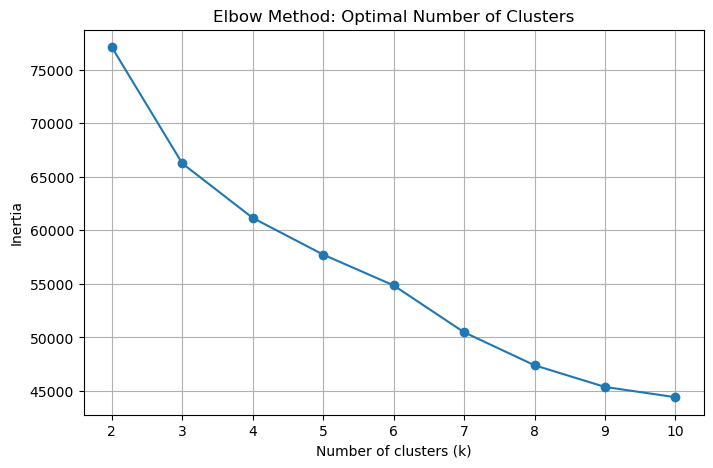

In [31]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Elbow method
inertia = []

K = range(2, 11)  # testing cluster counts from 2 to 10
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8,5))
plt.plot(K, inertia, marker='o')
plt.title('Elbow Method: Optimal Number of Clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


In [32]:
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df['cluster'] = clusters


In [33]:
df['cluster'].value_counts()



cluster
0    3314
3    2975
1    2682
2    1029
Name: count, dtype: int64

In [34]:
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df['cluster'] = clusters


In [35]:
df['cluster'].value_counts()


cluster
0    3314
3    2975
1    2682
2    1029
Name: count, dtype: int64

In [36]:
cluster_profile = df.groupby('cluster')[[
    'days_since_last_active',
    'tenure_days',
    'engagement_score',
    'ltv',
    'total_sessions',
    'avg_session_duration',
    'features_used_count',
    'support_tickets',
    'monthly_fee',
    'churned'
]].mean().round(2)

cluster_profile


,days_since_last_active,tenure_days,engagement_score,ltv,total_sessions,avg_session_duration,features_used_count,support_tickets,monthly_fee,churned
cluster,,,,,,,,,,
0,3.51,202.60,1461.01,97.92,39.20,10.90,3.74,0.30,15.50,0.18
1,25.25,349.20,4365.52,170.55,41.56,14.31,7.52,0.32,15.63,0.15
2,60.14,482.33,2248.41,562.72,39.83,11.69,4.90,0.28,35.00,0.17
3,101.43,570.95,1702.02,278.09,39.56,11.11,4.19,0.32,14.69,0.26


In [2]:
import pandas as pd

df = pd.read_csv("subscription_app_users_10k.csv")

df.head()

,user_id,signup_date,last_active_date,subscription_plan,monthly_fee,total_sessions,avg_session_duration,features_used_count,support_tickets,device_type,churned
0,1,2023-04-13,2024-12-29,Standard,20,39,15.979452,1,1,Android,0
1,2,2024-03-11,2024-12-10,Standard,20,48,11.295767,4,0,Web,0
2,3,2023-09-28,2024-05-17,Basic,10,42,3.784222,6,0,Android,1
3,4,2023-04-17,2024-03-03,Basic,10,45,10.195382,9,0,iOS,1
4,5,2023-03-13,2023-08-08,Basic,10,46,11.779901,5,1,Web,1


In [6]:
df.columns


Index(['user_id', 'signup_date', 'last_active_date', 'subscription_plan',
       'monthly_fee', 'total_sessions', 'avg_session_duration',
       'features_used_count', 'support_tickets', 'device_type', 'churned'],
      dtype='object')

In [7]:
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['last_active_date'] = pd.to_datetime(df['last_active_date'])


In [8]:
import datetime as dt
today = dt.datetime(2025, 1, 1)

df['days_since_last_active'] = (today - df['last_active_date']).dt.days
df['tenure_days'] = (today - df['signup_date']).dt.days

df['engagement_score'] = (
    df['total_sessions'] *
    df['avg_session_duration'] *
    df['features_used_count']
)

df['tenure_months'] = df['tenure_days'] / 30
df['ltv'] = df['tenure_months'] * df['monthly_fee']



In [9]:
df[['days_since_last_active', 'tenure_days', 'engagement_score', 'ltv']].head()


,days_since_last_active,tenure_days,engagement_score,ltv
0,3,629,623.198627,419.333333
1,22,296,2168.787319,197.333333
2,229,461,953.623963,153.666667
3,304,625,4129.129873,208.333333
4,512,660,2709.377122,220.000000


In [10]:
features = [
    'days_since_last_active',
    'tenure_days',
    'engagement_score',
    'ltv',
    'monthly_fee',
    'total_sessions',
    'avg_session_duration',
    'features_used_count',
    'support_tickets'
]

X = df[features]


In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [12]:
df.columns


Index(['user_id', 'signup_date', 'last_active_date', 'subscription_plan',
       'monthly_fee', 'total_sessions', 'avg_session_duration',
       'features_used_count', 'support_tickets', 'device_type', 'churned',
       'days_since_last_active', 'tenure_days', 'engagement_score',
       'tenure_months', 'ltv'],
      dtype='object')

In [13]:
df[['days_since_last_active', 'tenure_days', 'engagement_score', 'ltv']].head()



,days_since_last_active,tenure_days,engagement_score,ltv
0,3,629,623.198627,419.333333
1,22,296,2168.787319,197.333333
2,229,461,953.623963,153.666667
3,304,625,4129.129873,208.333333
4,512,660,2709.377122,220.000000


In [14]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df['cluster'] = clusters


In [15]:
df['cluster'].value_counts()


cluster
0    3314
3    2975
1    2682
2    1029
Name: count, dtype: int64

In [16]:
cluster_profile = df.groupby('cluster')[[
    'days_since_last_active',
    'tenure_days',
    'engagement_score',
    'ltv',
    'total_sessions',
    'avg_session_duration',
    'features_used_count',
    'support_tickets',
    'monthly_fee',
    'churned'
]].mean().round(2)

cluster_profile


,days_since_last_active,tenure_days,engagement_score,ltv,total_sessions,avg_session_duration,features_used_count,support_tickets,monthly_fee,churned
cluster,,,,,,,,,,
0,3.51,202.60,1461.01,97.92,39.20,10.90,3.74,0.30,15.50,0.18
1,25.25,349.20,4365.52,170.55,41.56,14.31,7.52,0.32,15.63,0.15
2,60.14,482.33,2248.41,562.72,39.83,11.69,4.90,0.28,35.00,0.17
3,101.43,570.95,1702.02,278.09,39.56,11.11,4.19,0.32,14.69,0.26


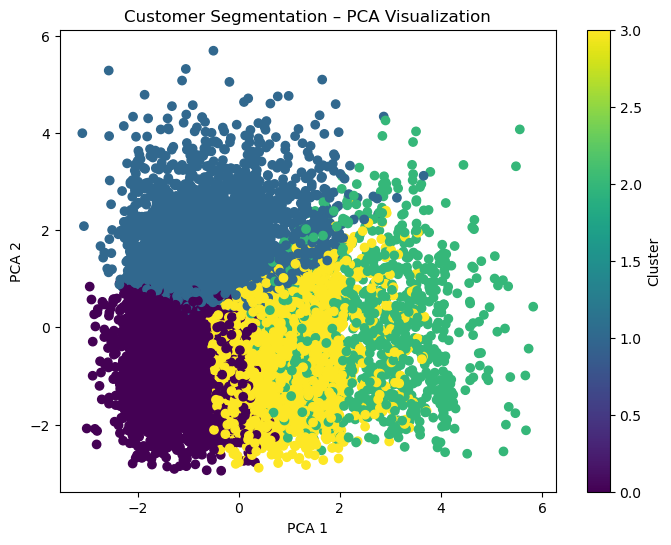

In [17]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

df['pca1'] = pca_result[:, 0]
df['pca2'] = pca_result[:, 1]

plt.figure(figsize=(8,6))
plt.scatter(df['pca1'], df['pca2'], c=df['cluster'], cmap='viridis')
plt.title('Customer Segmentation – PCA Visualization')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.colorbar(label='Cluster')
plt.show()
